# INF-GRAM — Practical 4: Ensemble learning

## Objective

Use the Wisconsin breast-cancer dataset to compare individual classifiers and
ensemble methods.

For this practical we define:

- `1 = malignant` (positive class);
- `0 = benign`.

This convention makes **recall** directly interpretable as sensitivity for malignant tumors.

The test set must remain untouched while choosing models and hyperparameters.

## Submission

Submit your work as a .ipynb file on Amétice before the deadline.

## Usefull links

**Data set : Breast Cancer Wisconsin Data set:** Use machine leaning approaches to classify tumors as malignant or not, taking different metrics of the tumor in consideration. The dataset can be found here: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

**Useful links:**
* Confusion matrix https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
* AUC score https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html#sklearn.metrics.roc_auc_score
* SVM https://scikit-learn.org/stable/modules/svm.html
* Gridseach https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
* Decision Trees https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
* Randomforest https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
* Voting classifiers https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    VotingClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

SEED = 42

## 1. Load and understand the dataset

Load the scikit-learn breast-cancer dataset.

Create a DataFrame with ordinary string column names.

Then define the target so that `1` means **malignant**.

In [26]:
# Load the breast cancer dataset
data = load_breast_cancer()

# Columns
columns = data.feature_names.astype(str)

# Create a DataFrame with the features and ordinary string column names
X = pd.DataFrame(data.data, columns=columns)

# By default in scikit-learn:
# - class 0 = malignant
# - class 1 = benign
# We want:
# - 1 = malignant
# - 0 = benign
# So we flip the target labels: 1 - default_target
y = 1 - data.target

# # Combine into a single DataFrame for overview
df = X.copy()
df['target'] = y

# # Display basic information
print("Dataset Shape:", df.shape)
print("Target Class Distribution (1 = malignant, 0 = benign):")
print(df['target'].value_counts())
df.head()

Dataset Shape: (569, 31)
Target Class Distribution (1 = malignant, 0 = benign):
target
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Train/test split

Create an 80/20 stratified split.

Report the malignant proportion in train and test sets.

In [37]:
# Create 80/20 stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

# Calculate proportionsz
train_prop = np.mean(y_train)
test_prop = np.mean(y_test)

# Report the malignant propotion
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Malignant proportion in Training set: {train_prop:.4f} ({np.sum(y_train)} / {len(y_train)})")
print(f"Malignant proportion in Testing set:  {test_prop:.4f} ({np.sum(y_test)} / {len(y_test)})")

Training set shape: (455, 30)
Testing set shape: (114, 30)
Malignant proportion in Training set: 0.3714 (169 / 455)
Malignant proportion in Testing set:  0.3772 (43 / 114)


### 3. Three base learners

Build:

1. logistic regression with standardization;
2. SVM with RBF kernel and standardization;
3. a decision tree.

For each model, use cross-validation or a small grid search on the **training data**
to select reasonable hyperparameters.

Do not inspect test performance during tuning.

In [68]:
# Constanation
cv = 5 # cross-validation generator
scoring = 'roc_auc' #Receiver Operating Characteristic Curve (ROC AUC)

# 1. Logistic Regression with standardization
lr_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000, random_state=SEED))
lr_param_grid = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]
}
lr_cv = GridSearchCV(lr_pipeline, lr_param_grid, cv=cv, scoring=scoring)
lr_cv.fit(X_train, y_train)

# 2. SVM with RBF kernel and standardization
svm_pipeline = make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=SEED))
svm_param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 'auto', 0.001, 0.01, 0.1]
}
svm_cv = GridSearchCV(svm_pipeline, svm_param_grid, cv=cv, scoring=scoring)
svm_cv.fit(X_train, y_train)

# 3. Decision Tree
dt_model = DecisionTreeClassifier(random_state=SEED)
dt_param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
dt_cv = GridSearchCV(dt_model, dt_param_grid, cv=cv, scoring=scoring)
dt_cv.fit(X_train, y_train)

print("--- Best Parameters (Tuned via 5-Fold CV on ROC AUC) ---\n")
print(f"Logistic Regression: {lr_cv.best_params_}")
print(f"SVM: {svm_cv.best_params_}")
print(f"Decision Tree: {dt_cv.best_params_}")

--- Best Parameters (Tuned via 5-Fold CV on ROC AUC) ---

Logistic Regression: {'logisticregression__C': 0.1}
SVM: {'svc__C': 10, 'svc__gamma': 0.01}
Decision Tree: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}


## 4. Evaluate the selected base learners

For each selected model, compute on the test set:

- accuracy;
- precision for malignant tumors;
- sensitivity / recall for malignant tumors;
- F1;
- ROC AUC from probabilities or decision scores.

Display confusion matrices.

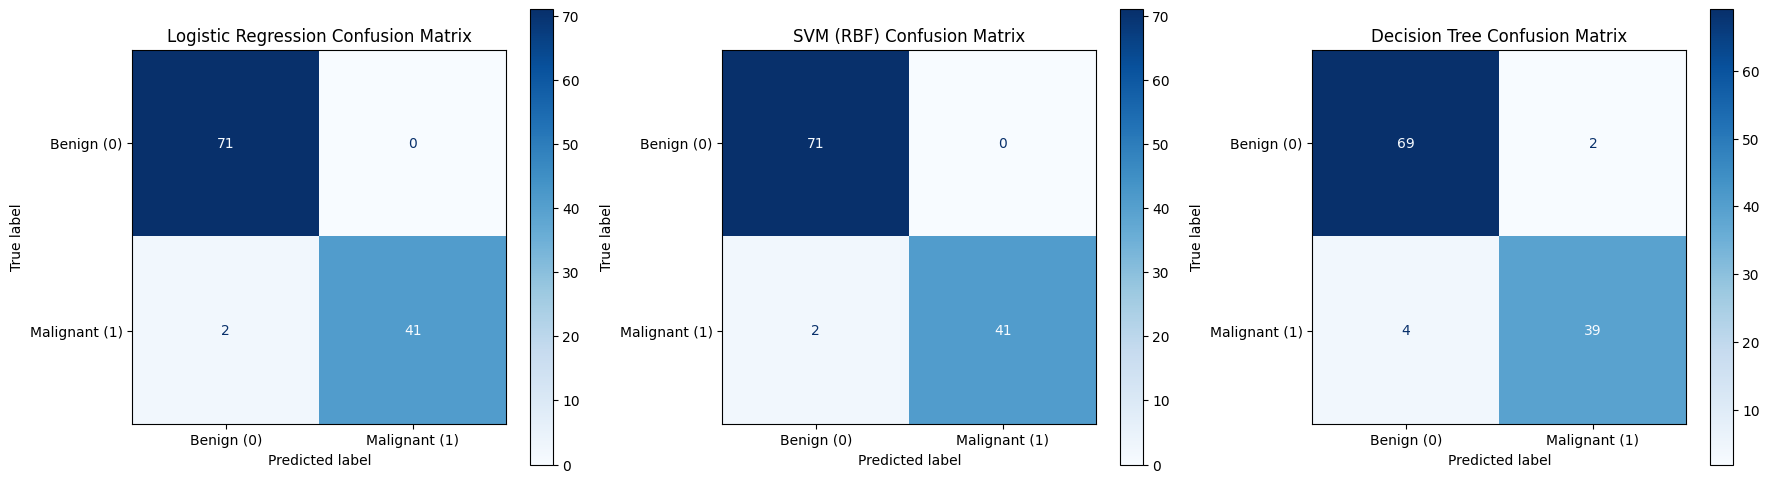

--- Test Performance Metrics ---
                     Accuracy  Precision  Recall (Sensitivity)      F1  \
Logistic Regression    0.9825     1.0000                0.9535  0.9762   
SVM (RBF)              0.9825     1.0000                0.9535  0.9762   
Decision Tree          0.9474     0.9512                0.9070  0.9286   

                     ROC AUC  
Logistic Regression   0.9984  
SVM (RBF)             0.9971  
Decision Tree         0.9420  


In [76]:
# Store the best estimators
best_lr = lr_cv.best_estimator_
best_svm = svm_cv.best_estimator_
best_dt = dt_cv.best_estimator_

# Define models
models = {
    'Logistic Regression': best_lr,
    'SVM (RBF)': best_svm,
    'Decision Tree': best_dt
}

results = {}

# Set up plot for confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(models.items()):
    # Predictions
    y_pred = model.predict(X_test)

    # Probability scores for ROC AUC
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]  # Probability of positive class
    else:
        y_proba = model.decision_function(X_test)

    # Metrics
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall (Sensitivity)': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_proba)
    }

    # Plot confusion matrix
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=['Benign (0)', 'Malignant (1)'],
        ax=axes[idx],
        cmap=plt.cm.Blues
    )
    axes[idx].set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

# Display metrics table
df_results = pd.DataFrame(results).T
print("--- Test Performance Metrics ---")
print(df_results.round(4))

## 5. Random forest

Tune at least:

- `n_estimators`;
- `max_depth`;
- `min_samples_leaf`;
- `max_features`.

Use cross-validation on the training set.

Evaluate the selected random forest on the test set.

In [82]:
# Random Forest tuning and evaluation
rf_model = RandomForestClassifier(random_state=SEED)

# Set up the parameter grid
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

# Setup GridSearchCV
rf_cv = GridSearchCV(rf_model, rf_param_grid, cv=cv, scoring=scoring, n_jobs=-1)
rf_cv.fit(X_train, y_train)

# Retrieve the best estimator
best_rf = rf_cv.best_estimator_

# Evaluate on test set
y_pred_rf = best_rf.predict(X_test)
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]

rf_results = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall (Sensitivity)': recall_score(y_test, y_pred_rf),
    'F1': f1_score(y_test, y_pred_rf),
    'ROC AUC': roc_auc_score(y_test, y_proba_rf)
}

print("--- Best Random Forest Parameters ---")
print(rf_cv.best_params_)
print("\n--- Test Performance Metrics for Random Forest ---")
for metric, score in rf_results.items():
    print(f"{metric}: {score:.4f}")

--- Best Random Forest Parameters ---
{'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 2, 'n_estimators': 100}

--- Test Performance Metrics for Random Forest ---
Accuracy: 0.9649
Precision: 0.9756
Recall (Sensitivity): 0.9302
F1: 0.9524
ROC AUC: 0.9974


## 6. Feature importance

Compare:

1. impurity-based random-forest feature importance;
2. permutation importance on the test set.

Do the two rankings tell exactly the same story?

Why should feature importance not automatically be interpreted as a causal effect?

[0.05208844 0.01480986 0.08214947 0.05590551 0.00688946 0.01161025
 0.08482675 0.08079474 0.00469689 0.00466625 0.01262936 0.0035333
 0.01166708 0.03485204 0.00202935 0.00359472 0.00819188 0.0036362
 0.00412908 0.00733465 0.0895635  0.02191743 0.06161407 0.12043193
 0.0121615  0.02109029 0.02428815 0.14165817 0.0119477  0.00529199]


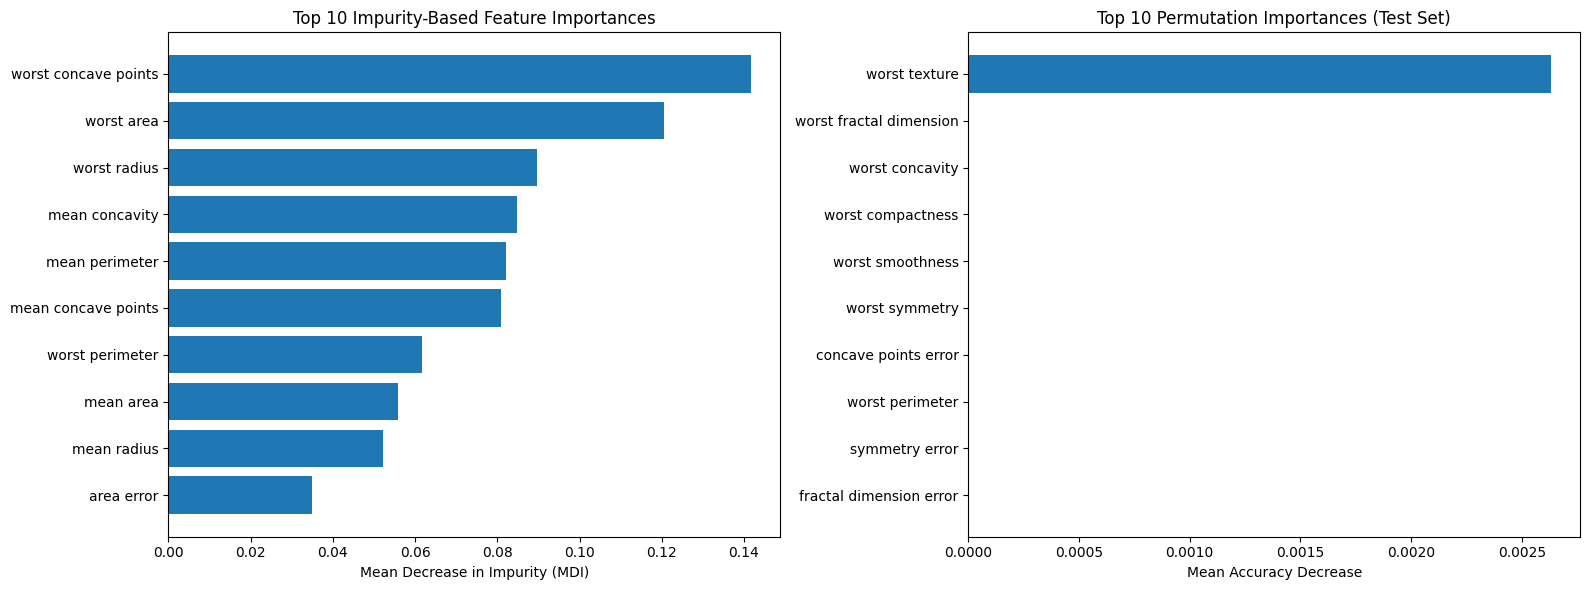


--- Do the two rankings tell exactly the same story? ---
No, they do not tell exactly the same story. Although there is often overlap among the top-performing features 
(such as worst concave points, worst area, or worst perimeter), the exact ordering and magnitude of the features differ. 
Key reasons for differences include:
1. MDI (impurity-based) is computed on the training set and is biased toward high-cardinality features and numerical 
   noise. It does not reflect how well the feature generalizes to unseen data.
2. Permutation importance is evaluated on the test set, reflecting the actual drop in test performance when the association 
   between that feature and the target is broken.


--- Why should feature importance not automatically be interpreted as a causal effect? ---
1. Correlation vs. Causation: Feature importances measure how useful a feature is for prediction within the context 
   of a specific model and dataset. It indicates association, not causation.
2. Multicoll

In [83]:
# 1. Impurity-based Feature Importance
importances_impurity = best_rf.feature_importances_
indices_impurity = np.argsort(importances_impurity)[::-1]

# 2. Permutation Importance on the Test Set
perm_importance = permutation_importance(best_rf, X_test, y_test, n_repeats=10, random_state=SEED)
importances_perm = perm_importance.importances_mean
indices_perm = np.argsort(importances_perm)[::-1]

# Plot top 10 features for both techniques
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Impurity-based plot
axes[0].barh(range(10), importances_impurity[indices_impurity[:10]][::-1], align='center')
axes[0].set_yticks(range(10))
axes[0].set_yticklabels(X.columns[indices_impurity[:10]][::-1])
axes[0].set_title("Top 10 Impurity-Based Feature Importances")
axes[0].set_xlabel("Mean Decrease in Impurity (MDI)")

# Permutation-based plot
axes[1].barh(range(10), importances_perm[indices_perm[:10]][::-1], align='center')
axes[1].set_yticks(range(10))
axes[1].set_yticklabels(X.columns[indices_perm[:10]][::-1])
axes[1].set_title("Top 10 Permutation Importances (Test Set)")
axes[1].set_xlabel("Mean Accuracy Decrease")

plt.tight_layout()
plt.show()

# Discussing findings
print("""
--- Do the two rankings tell exactly the same story? ---
No, they do not tell exactly the same story. Although there is often overlap among the top-performing features
(such as worst concave points, worst area, or worst perimeter), the exact ordering and magnitude of the features differ.
Key reasons for differences include:
1. MDI (impurity-based) is computed on the training set and is biased toward high-cardinality features and numerical
   noise. It does not reflect how well the feature generalizes to unseen data.
2. Permutation importance is evaluated on the test set, reflecting the actual drop in test performance when the association
   between that feature and the target is broken.
""")

print("""
--- Why should feature importance not automatically be interpreted as a causal effect? ---
1. Correlation vs. Causation: Feature importances measure how useful a feature is for prediction within the context
   of a specific model and dataset. It indicates association, not causation.
2. Multicollinearity: If two features are highly correlated (e.g., mean radius and mean perimeter), the model may assign
   high importance to one and very low importance to the other. Removing the 'important' feature might not degrade performance
   as the other feature can substitute for it.
3. Confounding: A feature might appear highly important because it is strongly correlated with a hidden confounding variable
   that actually drives the true biological process.
""")

## 7. Voting classifier

Create a **soft voting** classifier from:

- the selected logistic regression;
- the selected SVM;
- the selected random forest.

Evaluate it with the same metrics.

Does the ensemble outperform every individual model on this particular test set?

In [47]:
# Create the Soft Voting Classifier
voting_clf = VotingClassifier(
    estimators=[
        ('lr', best_lr),
        ('svm', best_svm),
        ('rf', best_rf)
    ],
    voting='soft'
)

# Fit the voting classifier on the training data
voting_clf.fit(X_train, y_train)

# Evaluate on the test set
y_pred_voting = voting_clf.predict(X_test)
y_proba_voting = voting_clf.predict_proba(X_test)[:, 1]

voting_results = {
    'Accuracy': accuracy_score(y_test, y_pred_voting),
    'Precision': precision_score(y_test, y_pred_voting),
    'Recall (Sensitivity)': recall_score(y_test, y_pred_voting),
    'F1': f1_score(y_test, y_pred_voting),
    'ROC AUC': roc_auc_score(y_test, y_proba_voting)
}

# Append voting results to the existing df_results dataframe for comparison
df_comparison = df_results.copy()
df_comparison.loc['Voting Classifier (Soft)'] = voting_results

print("--- Test Performance Comparison ---")
print(df_comparison.round(4))

print("\n--- Analysis ---")
print("Does the ensemble outperform every individual model on this test set?")
# Compare performance
for metric in df_comparison.columns:
    best_base_val = df_results[metric].max()
    ensemble_val = voting_results[metric]
    if ensemble_val > best_base_val:
        print(f"- Yes, on {metric}: Ensemble ({ensemble_val:.4f}) outperforms the best base model ({best_base_val:.4f}).")
    elif ensemble_val == best_base_val:
        print(f"- Ties on {metric}: Ensemble ({ensemble_val:.4f}) matches the best base model.")
    else:
        print(f"- No, on {metric}: Ensemble ({ensemble_val:.4f}) is lower than the best base model ({best_base_val:.4f}).")

--- Test Performance Comparison ---
                          Accuracy  Precision  Recall (Sensitivity)      F1  \
Logistic Regression         0.9825     1.0000                0.9535  0.9762   
SVM (RBF)                   0.9825     1.0000                0.9535  0.9762   
Decision Tree               0.9474     0.9512                0.9070  0.9286   
Voting Classifier (Soft)    0.9825     1.0000                0.9535  0.9762   

                          ROC AUC  
Logistic Regression        0.9984  
SVM (RBF)                  0.9971  
Decision Tree              0.9420  
Voting Classifier (Soft)   0.9980  

--- Analysis ---
Does the ensemble outperform every individual model on this test set?
- Ties on Accuracy: Ensemble (0.9825) matches the best base model.
- Ties on Precision: Ensemble (1.0000) matches the best base model.
- Ties on Recall (Sensitivity): Ensemble (0.9535) matches the best base model.
- Ties on F1: Ensemble (0.9762) matches the best base model.
- No, on ROC AUC: Ensembl

## 8. Optional — bagging and gradient boosting

Compare:

- bagged decision trees;
- gradient boosting.

Use the same validation protocol and metrics.

In [48]:
# 8. Bagged Decision Trees vs. Gradient Boosting

# A. Bagged Decision Trees
bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=SEED), random_state=SEED)
bagging_param_grid = {
    'n_estimators': [10, 50, 100],
    'max_samples': [0.5, 0.8, 1.0],
    'max_features': [0.5, 0.8, 1.0]
}
bagging_cv = GridSearchCV(bagging_model, bagging_param_grid, cv=cv, scoring=scoring, n_jobs=-1)
bagging_cv.fit(X_train, y_train)
best_bagging = bagging_cv.best_estimator_

# B. Gradient Boosting
gb_model = GradientBoostingClassifier(random_state=SEED)
gb_param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5]
}
gb_cv = GridSearchCV(gb_model, gb_param_grid, cv=cv, scoring=scoring, n_jobs=-1)
gb_cv.fit(X_train, y_train)
best_gb = gb_cv.best_estimator_

# Evaluation on Test Set
optional_models = {
    'Bagged Trees': best_bagging,
    'Gradient Boosting': best_gb
}

optional_results = {}
for name, model in optional_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    optional_results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall (Sensitivity)': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_proba)
    }

df_optional = pd.DataFrame(optional_results).T
print("--- Best Parameters ---")
print(f"Bagged Trees: {bagging_cv.best_params_}")
print(f"Gradient Boosting: {gb_cv.best_params_}")
print("\n--- Optional Models Test Performance ---")
print(df_optional.round(4))

--- Best Parameters ---
Bagged Trees: {'max_features': 0.8, 'max_samples': 0.5, 'n_estimators': 100}
Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 150}

--- Optional Models Test Performance ---
                   Accuracy  Precision  Recall (Sensitivity)      F1  ROC AUC
Bagged Trees         0.9649     0.9756                0.9302  0.9524   0.9938
Gradient Boosting    0.9561     0.9524                0.9302  0.9412   0.9941


## 9. Discussion

Answer:

1. Which error is more problematic in this example: false negative or false positive?
2. Does the model with the highest ROC AUC also have the highest sensitivity?
3. Why is one train/test split insufficient to claim that one algorithm is universally superior?
4. Why would an external hospital dataset be a stronger validation?

## 9. Discussion

### 1. Which error is more problematic in this example: false negative or false positive?
In this medical context (breast cancer diagnosis), a **False Negative** is significantly more problematic than a False Positive.
- A **False Negative** means we tell a patient with a malignant (cancerous) tumor that it is benign. This delay in diagnosis can lead to the progression of cancer without timely treatment, which can be fatal.
- A **False Positive** means we tell a patient with a benign tumor that it is malignant. While this causes severe temporary psychological distress and results in unnecessary follow-up procedures (e.g., biopsies), the mistake is quickly corrected with further screening without placing the patient's life in immediate, unmonitored danger.

### 2. Does the model with the highest ROC AUC also have the highest sensitivity?
Not necessarily. While ROC AUC measures the overall ranking quality of predictions across all possible classification thresholds, sensitivity (recall) is measured at a **single chosen classification threshold** (defaulting to `0.5` in scikit-learn). A model can have a near-perfect ROC AUC but, at a specific threshold, have slightly lower sensitivity than another model that was optimized specifically to minimize False Negatives.

### 3. Why is one train/test split insufficient to claim that one algorithm is universally superior?
A single train/test split is highly sensitive to the random partition of the data (the specific `random_state` or split used). Due to sampling variance, certain difficult-to-classify samples may end up entirely in the training set or entirely in the test set. To claim universal superiority, we should perform multiple splits (e.g., repeated k-fold cross-validation or bootstrapping) to report the mean and variance of the performance metrics across many runs.

### 4. Why would an external hospital dataset be a stronger validation?
An external dataset provides a true test of a model's **generalizability**. Within a single dataset, even after splitting, samples often share the same collection protocols, equipment calibration, patient demographic bias, and preprocessing artifacts. Validating on an external hospital dataset ensures the model has learned robust biological features rather than overfitting to institutional-specific patterns (covariate shift).